In [3]:
import sys, pandas, sklearn, shap
print(sys.executable)
print(pandas.__version__, sklearn.__version__, shap.__version__)

/Users/ayumumizushima/cardio-risk/.venv/bin/python3
3.0.6 1.9.1 0.53.0


In [4]:
import os
print(os.listdir("../data"))

[]


In [5]:
import os
print(os.listdir("../data"))

['extention of Z-Alizadeh sani dataset.xlsx']


In [6]:
import os
import pandas as pd

files = [f for f in os.listdir("../data") if f.lower().endswith((".xlsx", ".xls", ".csv"))]
print("Found:", files)

path = os.path.join("../data", files[0])
if path.lower().endswith(".csv"):
    df = pd.read_csv(path)
else:
    df = pd.read_excel(path)

print("Shape:", df.shape)
print(df.columns.tolist())
df.head()

Found: ['extention of Z-Alizadeh sani dataset.xlsx']
Shape: (303, 59)
['Age', 'Weight', 'Length', 'Sex', 'BMI', 'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'Obesity', 'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP', 'BP', 'PR', 'Edema', 'Weak Peripheral Pulse', 'Lung rales', 'Systolic Murmur', 'Diastolic Murmur', 'Typical Chest Pain', 'Dyspnea', 'Function Class', 'Atypical', 'Nonanginal', 'Exertional CP', 'LowTH Ang', 'Q Wave', 'St Elevation', 'St Depression', 'Tinversion', 'LVH', 'Poor R Progression', 'BBB', 'FBS', 'CR', 'TG', 'LDL', 'HDL', 'BUN', 'ESR', 'HB', 'K', 'Na', 'WBC', 'Lymph', 'Neut', 'PLT', 'EF-TTE', 'Region RWMA', 'VHD', 'LAD', 'LCX', 'RCA', 'Cath']


,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,...,Lymph,Neut,PLT,EF-TTE,Region RWMA,VHD,LAD,LCX,RCA,Cath
0,53,90,175,Male,29.387755,0,1,1,0,0,...,39,52,261,50,0,N,Stenotic,Normal,Stenotic,CAD
1,67,70,157,Fmale,28.398718,0,1,0,0,0,...,38,55,165,40,4,N,Stenotic,Stenotic,Normal,CAD
2,54,54,164,Male,20.077335,0,0,1,0,0,...,38,60,230,40,2,mild,Stenotic,Normal,Normal,CAD
3,66,67,158,Fmale,26.838648,0,1,0,0,0,...,18,72,742,55,0,Severe,Normal,Normal,Normal,Normal
4,50,87,153,Fmale,37.165193,0,1,0,0,0,...,55,39,274,50,0,Severe,Normal,Normal,Normal,Normal


In [7]:
print(df.dtypes)
print(df.isna().sum())

Age                        int64
Weight                     int64
Length                     int64
Sex                          str
BMI                      float64
DM                         int64
HTN                        int64
Current Smoker             int64
EX-Smoker                  int64
FH                         int64
Obesity                      str
CRF                          str
CVA                          str
Airway disease               str
Thyroid Disease              str
CHF                          str
DLP                          str
BP                         int64
PR                         int64
Edema                      int64
Weak Peripheral Pulse        str
Lung rales                   str
Systolic Murmur              str
Diastolic Murmur             str
Typical Chest Pain         int64
Dyspnea                      str
Function Class             int64
Atypical                     str
Nonanginal                   str
Exertional CP                str
LowTH Ang 

In [8]:
# 1) Missing values overall
print("Total missing:", int(df.isna().sum().sum()))
print(df.isna().sum()[df.isna().sum() > 0])
print()

# 2) Unique values in every non-numeric column
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    print(c, "->", sorted(df[c].dropna().astype(str).unique().tolist()))
print()

# 3) How balanced are the four targets?
for t in ["Cath", "LAD", "LCX", "RCA"]:
    print(t, df[t].value_counts().to_dict())

Total missing: 0
Series([], dtype: int64)

Sex -> ['Fmale', 'Male']
Obesity -> ['N', 'Y']
CRF -> ['N', 'Y']
CVA -> ['N', 'Y']
Airway disease -> ['N', 'Y']
Thyroid Disease -> ['N', 'Y']
CHF -> ['N', 'Y']
DLP -> ['N', 'Y']
Weak Peripheral Pulse -> ['N', 'Y']
Lung rales -> ['N', 'Y']
Systolic Murmur -> ['N', 'Y']
Diastolic Murmur -> ['N', 'Y']
Dyspnea -> ['N', 'Y']
Atypical -> ['N', 'Y']
Nonanginal -> ['N', 'Y']
Exertional CP -> ['N']
LowTH Ang -> ['N', 'Y']
LVH -> ['N', 'Y']
Poor R Progression -> ['N', 'Y']
BBB -> ['LBBB', 'N', 'RBBB']
VHD -> ['Moderate', 'N', 'Severe', 'mild']
LAD -> ['Normal', 'Stenotic']
LCX -> ['Normal', 'Stenotic']
RCA -> ['Normal', 'Stenotic']
Cath -> ['CAD', 'Normal']

Cath {'CAD': 216, 'Normal': 87}
LAD {'Stenotic': 177, 'Normal': 126}
LCX {'Normal': 184, 'Stenotic': 119}
RCA {'Normal': 189, 'Stenotic': 114}


In [9]:
%%writefile ../preprocess.py
import pandas as pd

TARGET_COLS = ["Cath", "LAD", "LCX", "RCA"]   # never used as model inputs
VHD_ORDER = {"N": 0, "mild": 1, "Moderate": 2, "Severe": 3}

def clean_features(df):
    """Raw dataset rows -> all-numeric feature table. Target columns are always removed."""
    X = df.drop(columns=[c for c in TARGET_COLS if c in df.columns]).copy()
    X = X.drop(columns=["Exertional CP"], errors="ignore")   # constant column
    X["Sex"] = X["Sex"].map({"Male": 1, "Fmale": 0, "Female": 0})
    X["VHD"] = X["VHD"].map(VHD_ORDER)
    X["BBB_LBBB"] = (X["BBB"] == "LBBB").astype(int)
    X["BBB_RBBB"] = (X["BBB"] == "RBBB").astype(int)
    X = X.drop(columns=["BBB"])
    for c in X.columns:                      # remaining text columns are Y/N
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].map({"Y": 1, "N": 0})
    return X

def get_targets(df):
    """1 = CAD / Stenotic, 0 = Normal."""
    return {
        "CAD": (df["Cath"] == "CAD").astype(int),
        "LAD": (df["LAD"] == "Stenotic").astype(int),
        "LCX": (df["LCX"] == "Stenotic").astype(int),
        "RCA": (df["RCA"] == "Stenotic").astype(int),
    }

Writing ../preprocess.py


In [10]:
import sys
sys.path.append("..")
from preprocess import clean_features, get_targets

X = clean_features(df)
y = get_targets(df)

print(X.shape)
print("Missing after cleaning:", int(X.isna().sum().sum()))
print("Non-numeric columns left:", [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])])
print("Leaky columns present:", [c for c in ["Cath","LAD","LCX","RCA"] if c in X.columns])

(303, 55)
Missing after cleaning: 0
Non-numeric columns left: []
Leaky columns present: []


In [11]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
}
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

rows = []
for target, labels in y.items():
    for name, model in models.items():
        res = cross_validate(model, X, labels, cv=cv, scoring=scoring, n_jobs=-1)
        row = {"target": target, "model": name}
        row.update({m: round(res[f"test_{m}"].mean(), 3) for m in scoring})
        rows.append(row)

results = pd.DataFrame(rows)
results

,target,model,accuracy,precision,recall,f1,roc_auc
0,CAD,LogReg,0.835,0.916,0.847,0.879,0.909
1,CAD,RandomForest,0.870,0.908,0.912,0.909,0.927
2,LAD,LogReg,0.719,0.781,0.727,0.750,0.803
3,LAD,RandomForest,0.795,0.807,0.859,0.830,0.852
4,LCX,LogReg,0.603,0.500,0.568,0.528,0.640
5,LCX,RandomForest,0.683,0.607,0.563,0.582,0.725
6,RCA,LogReg,0.647,0.531,0.612,0.563,0.696
7,RCA,RandomForest,0.671,0.578,0.497,0.527,0.710


In [12]:
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier

models2 = {
    "ExtraTrees": ExtraTreesClassifier(n_estimators=500, class_weight="balanced", random_state=42),
    "HistGB": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=42),
}

rows2 = []
for target, labels in y.items():
    for name, model in models2.items():
        res = cross_validate(model, X, labels, cv=cv, scoring=scoring, n_jobs=-1)
        row = {"target": target, "model": name}
        row.update({m: round(res[f"test_{m}"].mean(), 3) for m in scoring})
        rows2.append(row)

results = pd.concat([results, pd.DataFrame(rows2)], ignore_index=True)
results.sort_values(["target", "roc_auc"], ascending=[True, False])

,target,model,accuracy,precision,recall,f1,roc_auc
1,CAD,RandomForest,0.870,0.908,0.912,0.909,0.927
8,CAD,ExtraTrees,0.869,0.896,0.924,0.910,0.927
0,CAD,LogReg,0.835,0.916,0.847,0.879,0.909
9,CAD,HistGB,0.864,0.893,0.923,0.907,0.905
3,LAD,RandomForest,0.795,0.807,0.859,0.830,0.852
10,LAD,ExtraTrees,0.795,0.793,0.885,0.835,0.839
11,LAD,HistGB,0.753,0.782,0.810,0.793,0.808
2,LAD,LogReg,0.719,0.781,0.727,0.750,0.803
13,LCX,HistGB,0.690,0.632,0.516,0.565,0.736
5,LCX,RandomForest,0.683,0.607,0.563,0.582,0.725


In [13]:
import joblib
from sklearn.base import clone

all_models = {**models, **models2}
best = results.loc[results.groupby("target")["roc_auc"].idxmax()]
print(best[["target", "model", "accuracy", "f1", "roc_auc"]])

for _, r in best.iterrows():
    m = clone(all_models[r["model"]])
    m.fit(X, y[r["target"]])
    joblib.dump(m, f"../models/{r['target']}.joblib")

joblib.dump(list(X.columns), "../models/feature_columns.joblib")
results.to_csv("../models/cv_results.csv", index=False)
print("Saved:", sorted(os.listdir("../models")))

   target         model  accuracy     f1  roc_auc
1     CAD  RandomForest     0.870  0.909    0.927
3     LAD  RandomForest     0.795  0.830    0.852
13    LCX        HistGB     0.690  0.565    0.736
14    RCA    ExtraTrees     0.668  0.456    0.732
Saved: ['CAD.joblib', 'LAD.joblib', 'LCX.joblib', 'RCA.joblib', 'cv_results.csv', 'feature_columns.joblib']


In [14]:
rf_lcx = clone(models["RandomForest"])
rf_lcx.fit(X, y["LCX"])
joblib.dump(rf_lcx, "../models/LCX.joblib")

# Sanity check: predicted probabilities for the first patient in the dataset
import numpy as np
row = X.iloc[[0]]
for t in ["CAD", "LAD", "LCX", "RCA"]:
    m = joblib.load(f"../models/{t}.joblib")
    print(t, "probability:", round(float(m.predict_proba(row)[0, 1]), 3), "| actual:", int(y[t].iloc[0]))

CAD probability: 0.79 | actual: 1
LAD probability: 0.697 | actual: 1
LCX probability: 0.113 | actual: 0
RCA probability: 1.0 | actual: 1


In [15]:
import json

meta = {
    "columns": list(X.columns),
    "defaults": {c: float(X[c].median()) for c in X.columns},
    "ranges": {c: [float(X[c].min()), float(X[c].max())] for c in X.columns},
    "binary": [c for c in X.columns if set(X[c].unique()) <= {0, 1}],
}
json.dump(meta, open("../models/feature_meta.json", "w"), indent=1)

vessels = y["LAD"] + y["LCX"] + y["RCA"]
groups = {
    "Multi-vessel disease (from dataset)": vessels == 3,
    "LAD only (from dataset)": (y["LAD"] == 1) & (y["LCX"] == 0) & (y["RCA"] == 0),
    "No disease (from dataset)": (y["CAD"] == 0) & (vessels == 0),
}
examples = {name: {k: float(v) for k, v in X[mask].iloc[0].items()}
            for name, mask in groups.items() if mask.any()}
json.dump(examples, open("../models/examples.json", "w"), indent=1)
print(list(examples))

['Multi-vessel disease (from dataset)', 'LAD only (from dataset)', 'No disease (from dataset)']


In [16]:
%%writefile ../api.py
import json
from pathlib import Path
import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from fastapi.staticfiles import StaticFiles
from pydantic import BaseModel

ROOT = Path(__file__).parent
M = ROOT / "models"
META = json.load(open(M / "feature_meta.json"))
EXAMPLES = json.load(open(M / "examples.json"))
COLUMNS = joblib.load(M / "feature_columns.joblib")
MODELS = {t: joblib.load(M / f"{t}.joblib") for t in ["CAD", "LAD", "LCX", "RCA"]}

app = FastAPI(title="Cardiac risk API (decision support / education only)")

class Patient(BaseModel):
    features: dict[str, float]

@app.get("/api/meta")
def meta():
    return {**META, "examples": EXAMPLES}

@app.post("/api/predict")
def predict(p: Patient):
    unknown = [k for k in p.features if k not in COLUMNS]
    if unknown:
        raise HTTPException(422, f"Unknown features: {unknown}")
    row = {**META["defaults"], **p.features}
    X = pd.DataFrame([row])[COLUMNS]
    return {t: float(m.predict_proba(X)[0, 1]) for t, m in MODELS.items()}

app.mount("/", StaticFiles(directory=ROOT / "web", html=True), name="web")

Writing ../api.py


In [17]:
%%writefile ../requirements.txt
pandas==3.0.6
numpy
scikit-learn==1.9.1
shap==0.53.0
joblib
fastapi
uvicorn[standard]

Writing ../requirements.txt


In [18]:
%%writefile ../api.py
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import shap
from fastapi import FastAPI, HTTPException
from fastapi.staticfiles import StaticFiles
from pydantic import BaseModel

ROOT = Path(__file__).parent
M = ROOT / "models"
META = json.load(open(M / "feature_meta.json"))
EXAMPLES = json.load(open(M / "examples.json"))
COLUMNS = joblib.load(M / "feature_columns.joblib")
TARGETS = ["CAD", "LAD", "LCX", "RCA"]
MODELS = {t: joblib.load(M / f"{t}.joblib") for t in TARGETS}
EXPLAINERS = {t: shap.TreeExplainer(m) for t, m in MODELS.items()}
TOP_N = 8

app = FastAPI(title="Cardiac risk API (decision support / education only)")

class Patient(BaseModel):
    features: dict[str, float]

def explain(t, X):
    sv = EXPLAINERS[t](X, check_additivity=False)
    vals = np.asarray(sv.values)
    vals = vals[0, :, 1] if vals.ndim == 3 else vals[0]
    base = np.asarray(sv.base_values)
    base = float(base[0, 1]) if base.ndim == 2 else float(np.ravel(base)[0])
    order = np.argsort(-np.abs(vals))[:TOP_N]
    return {"base": base,
            "top": [{"feature": COLUMNS[i], "value": float(X.iloc[0, i]),
                     "contribution": float(vals[i])} for i in order]}

@app.get("/api/meta")
def meta():
    return {**META, "examples": EXAMPLES}

@app.post("/api/predict")
def predict(p: Patient):
    unknown = [k for k in p.features if k not in COLUMNS]
    if unknown:
        raise HTTPException(422, f"Unknown features: {unknown}")
    row = {**META["defaults"], **p.features}
    X = pd.DataFrame([row])[COLUMNS]
    out = {t: float(MODELS[t].predict_proba(X)[0, 1]) for t in TARGETS}
    out["explanations"] = {t: explain(t, X) for t in TARGETS}
    return out

app.mount("/", StaticFiles(directory=ROOT / "web", html=True), name="web")

Overwriting ../api.py


In [19]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support, accuracy_score, brier_score_loss)
from sklearn.calibration import calibration_curve

os.makedirs("../docs/figures", exist_ok=True)
all_models = {**models, **models2}
deployed = {"CAD": "RandomForest", "LAD": "RandomForest", "LCX": "RandomForest", "RCA": "ExtraTrees"}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = {t: cross_val_predict(clone(all_models[name]), X, y[t], cv=skf,
                            method="predict_proba", n_jobs=-1)[:, 1]
       for t, name in deployed.items()}
print("done")

done


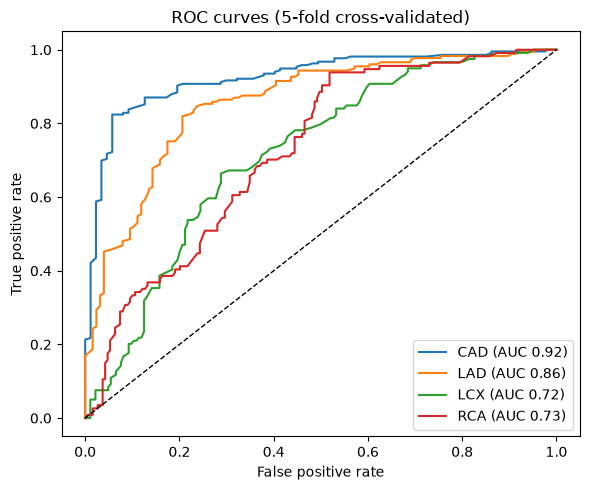

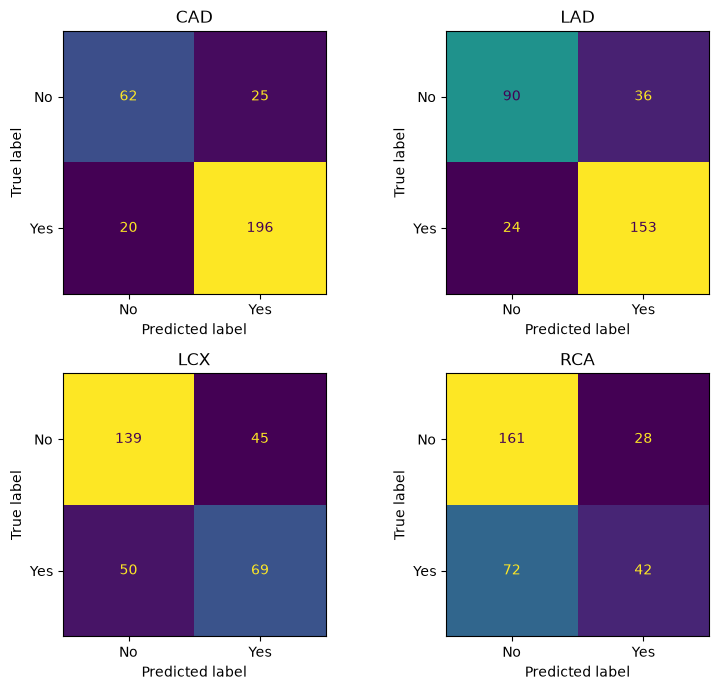

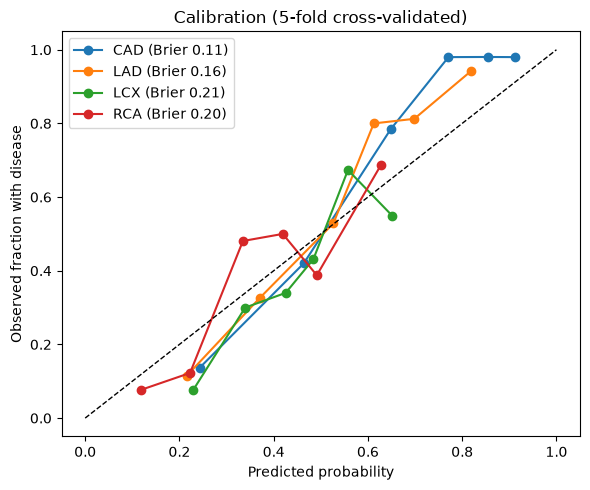

In [20]:
# ROC curves
fig, ax = plt.subplots(figsize=(6, 5))
for t in oof:
    fpr, tpr, _ = roc_curve(y[t], oof[t])
    ax.plot(fpr, tpr, label=f"{t} (AUC {roc_auc_score(y[t], oof[t]):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves (5-fold cross-validated)"); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig("../docs/figures/roc.png", dpi=200); plt.show()

# Confusion matrices at the default 0.5 cut-off
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for ax, t in zip(axes.ravel(), oof):
    cm = confusion_matrix(y[t], oof[t] >= 0.5)
    ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(ax=ax, colorbar=False)
    ax.set_title(t)
fig.tight_layout(); fig.savefig("../docs/figures/confusion.png", dpi=200); plt.show()

# Calibration: do predicted probabilities match how often disease really occurs?
fig, ax = plt.subplots(figsize=(6, 5))
for t in oof:
    frac, mean = calibration_curve(y[t], oof[t], n_bins=6, strategy="quantile")
    ax.plot(mean, frac, marker="o", label=f"{t} (Brier {brier_score_loss(y[t], oof[t]):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed fraction with disease")
ax.set_title("Calibration (5-fold cross-validated)"); ax.legend()
fig.tight_layout(); fig.savefig("../docs/figures/calibration.png", dpi=200); plt.show()

,target,model,accuracy,precision,recall,f1,roc_auc,brier
0,CAD,RandomForest,0.851,0.887,0.907,0.897,0.924,0.113
1,LAD,RandomForest,0.802,0.810,0.864,0.836,0.856,0.163
2,LCX,RandomForest,0.686,0.605,0.580,0.592,0.718,0.212
3,RCA,ExtraTrees,0.670,0.600,0.368,0.457,0.725,0.201


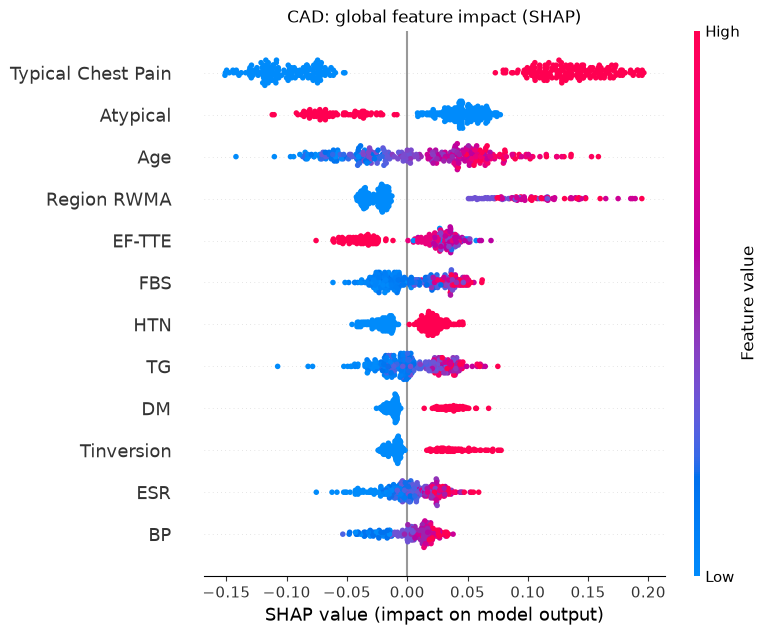

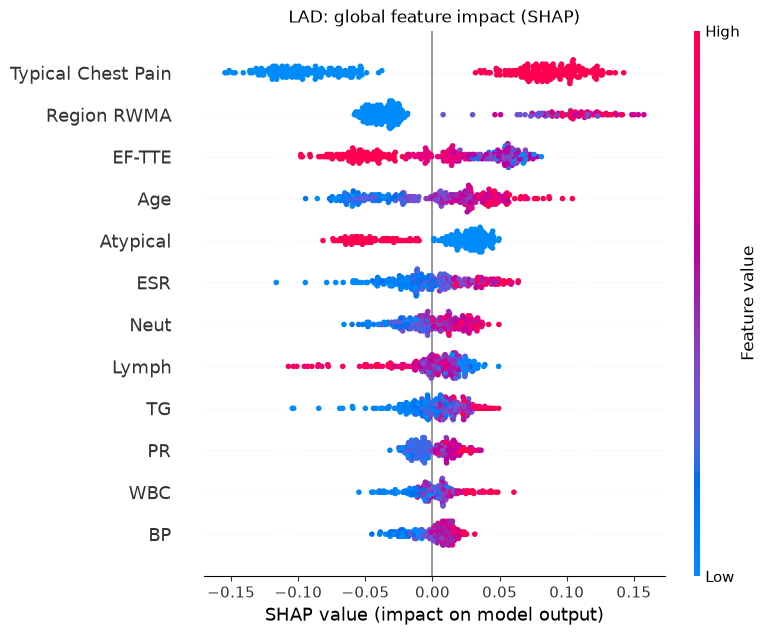

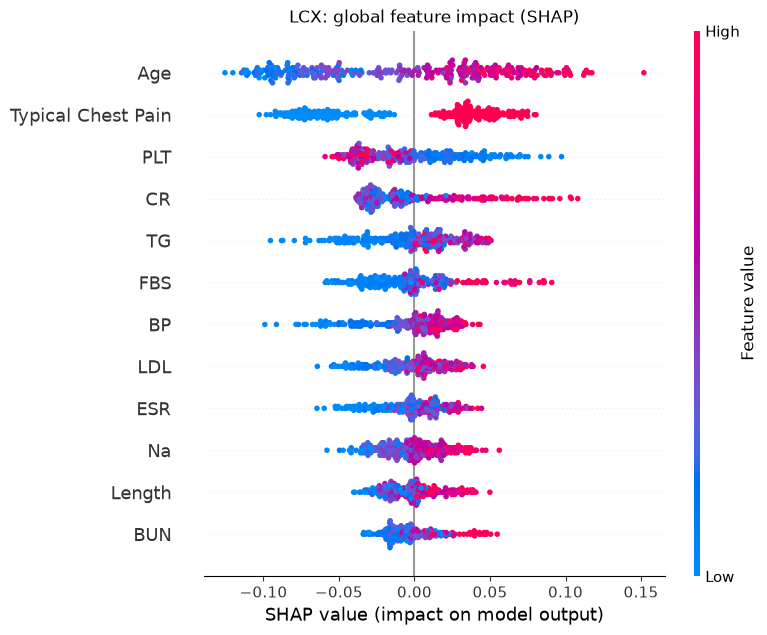

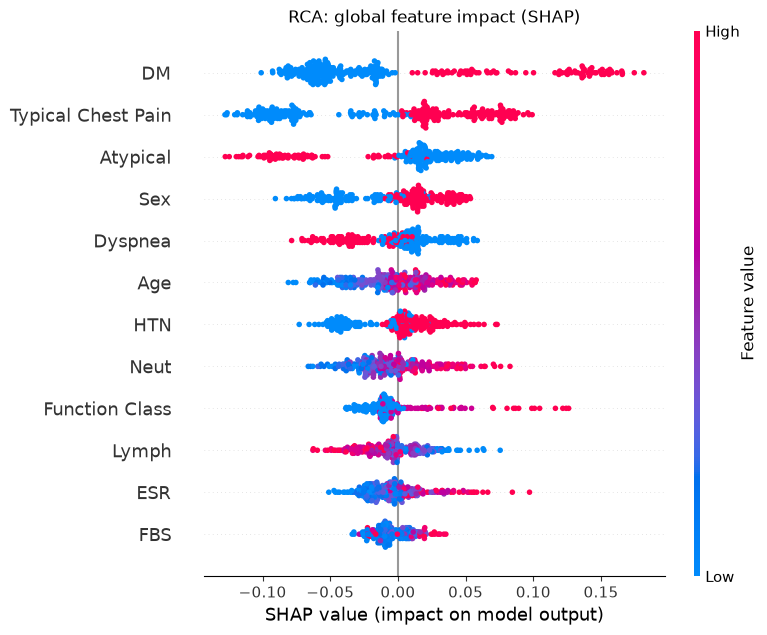

In [21]:
import shap, joblib

rows = []
for t in oof:
    pred = oof[t] >= 0.5
    p, r, f, _ = precision_recall_fscore_support(y[t], pred, average="binary")
    rows.append({"target": t, "model": deployed[t], "accuracy": accuracy_score(y[t], pred),
                 "precision": p, "recall": r, "f1": f,
                 "roc_auc": roc_auc_score(y[t], oof[t]), "brier": brier_score_loss(y[t], oof[t])})
final = pd.DataFrame(rows).round(3)
final.to_csv("../docs/final_metrics.csv", index=False)
display(final)

for t in ["CAD", "LAD", "LCX", "RCA"]:
    ex = shap.TreeExplainer(joblib.load(f"../models/{t}.joblib"))(X, check_additivity=False)
    v = ex.values[:, :, 1] if ex.values.ndim == 3 else ex.values
    plt.figure()
    shap.summary_plot(v, X, show=False, max_display=12)
    plt.title(f"{t}: global feature impact (SHAP)")
    plt.savefig(f"../docs/figures/shap_{t}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [22]:
%%writefile ../train.py
"""Train all models with nested cross-validation; save models, metrics, figures.
Run from the project root:  python train.py"""
import json
from pathlib import Path
import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.calibration import calibration_curve
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, brier_score_loss,
                             confusion_matrix, precision_recall_fscore_support,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from preprocess import clean_features, get_targets

ROOT, SEED = Path(__file__).parent, 42
TARGETS = ["CAD", "LAD", "LCX", "RCA"]
(ROOT / "models").mkdir(exist_ok=True)
(ROOT / "docs" / "figures").mkdir(parents=True, exist_ok=True)

data_file = next(p for p in sorted((ROOT / "data").iterdir())
                 if p.suffix.lower() in {".xlsx", ".xls", ".csv"})
df = pd.read_csv(data_file) if data_file.suffix.lower() == ".csv" else pd.read_excel(data_file)
X, y = clean_features(df), get_targets(df)
print("Data:", data_file.name, X.shape)

GRID = {"min_samples_leaf": [1, 3, 5], "max_features": ["sqrt", 0.3],
        "class_weight": [None, "balanced"]}
CANDIDATES = {
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=SEED),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=400, random_state=SEED),
}
outer = StratifiedKFold(5, shuffle=True, random_state=SEED)
inner = StratifiedKFold(3, shuffle=True, random_state=SEED)

def search(est, cv):
    return GridSearchCV(est, GRID, cv=cv, scoring="roc_auc", n_jobs=-1)

def ci(yt, p, fn, n=1000):
    rng, vals = np.random.default_rng(SEED), []
    for _ in range(n):
        s = rng.integers(0, len(yt), len(yt))
        if len(np.unique(yt[s])) == 2:
            vals.append(fn(yt[s], p[s]))
    return np.percentile(vals, [2.5, 97.5])

final, oof, rows, info = {}, {}, [], {}
for t in TARGETS:
    yt = y[t].values
    best_auc = -1
    for name, est in CANDIDATES.items():
        p = cross_val_predict(search(est, inner), X, yt, cv=outer, method="predict_proba")[:, 1]
        auc = roc_auc_score(yt, p)
        print(f"{t:4s} {name:12s} nested-CV AUC {auc:.3f}")
        if auc > best_auc:
            best_auc, best_name, best_p = auc, name, p
    gs = search(CANDIDATES[best_name], StratifiedKFold(5, shuffle=True, random_state=SEED)).fit(X, yt)
    final[t], oof[t] = gs.best_estimator_, best_p
    joblib.dump(gs.best_estimator_, ROOT / "models" / f"{t}.joblib")
    pred = best_p >= 0.5
    pr, rc, f1, _ = precision_recall_fscore_support(yt, pred, average="binary")
    lo, hi = ci(yt, best_p, roc_auc_score)
    rows.append({"target": t, "model": best_name, "accuracy": accuracy_score(yt, pred),
                 "precision": pr, "recall": rc, "f1": f1, "roc_auc": auc if False else best_auc,
                 "auc_ci_low": lo, "auc_ci_high": hi, "brier": brier_score_loss(yt, best_p)})
    info[t] = {"model": best_name, "params": {k: (v if v is None or isinstance(v, (int, float, str)) else str(v))
                                             for k, v in gs.best_params_.items()}}
    print(f"  -> {t}: {best_name} {gs.best_params_}")

metrics = pd.DataFrame(rows).round(3)
metrics.to_csv(ROOT / "docs" / "final_metrics.csv", index=False)
json.dump(info, open(ROOT / "models" / "model_info.json", "w"), indent=1)
print(metrics.to_string())

# Serving metadata (same format as before)
joblib.dump(list(X.columns), ROOT / "models" / "feature_columns.joblib")
meta = {"columns": list(X.columns),
        "defaults": {c: float(X[c].median()) for c in X.columns},
        "ranges": {c: [float(X[c].min()), float(X[c].max())] for c in X.columns},
        "binary": [c for c in X.columns if set(X[c].unique()) <= {0, 1}]}
json.dump(meta, open(ROOT / "models" / "feature_meta.json", "w"), indent=1)
vessels = y["LAD"] + y["LCX"] + y["RCA"]
groups = {"Multi-vessel disease (from dataset)": vessels == 3,
          "LAD only (from dataset)": (y["LAD"] == 1) & (y["LCX"] == 0) & (y["RCA"] == 0),
          "No disease (from dataset)": (y["CAD"] == 0) & (vessels == 0)}
examples = {n: {k: float(v) for k, v in X[m].iloc[0].items()} for n, m in groups.items() if m.any()}
json.dump(examples, open(ROOT / "models" / "examples.json", "w"), indent=1)

# Figures
fig, ax = plt.subplots(figsize=(6, 5))
for t in TARGETS:
    fpr, tpr, _ = roc_curve(y[t], oof[t])
    ax.plot(fpr, tpr, label=f"{t} (AUC {roc_auc_score(y[t], oof[t]):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (nested 5-fold CV)")
ax.legend(loc="lower right"); fig.tight_layout(); fig.savefig(ROOT / "docs/figures/roc.png", dpi=200); plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for ax, t in zip(axes.ravel(), TARGETS):
    ConfusionMatrixDisplay(confusion_matrix(y[t], oof[t] >= 0.5), display_labels=["No", "Yes"]).plot(ax=ax, colorbar=False)
    ax.set_title(t)
fig.tight_layout(); fig.savefig(ROOT / "docs/figures/confusion.png", dpi=200); plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 5))
for t in TARGETS:
    frac, mean = calibration_curve(y[t], oof[t], n_bins=6, strategy="quantile")
    ax.plot(mean, frac, marker="o", label=f"{t} (Brier {brier_score_loss(y[t], oof[t]):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="Predicted probability", ylabel="Observed fraction with disease", title="Calibration (nested 5-fold CV)")
ax.legend(); fig.tight_layout(); fig.savefig(ROOT / "docs/figures/calibration.png", dpi=200); plt.close(fig)

for t in TARGETS:
    ex = shap.TreeExplainer(final[t])(X, check_additivity=False)
    v = ex.values[:, :, 1] if ex.values.ndim == 3 else ex.values
    plt.figure(); shap.summary_plot(v, X, show=False, max_display=12)
    plt.title(f"{t}: global feature impact (SHAP)")
    plt.savefig(ROOT / f"docs/figures/shap_{t}.png", dpi=200, bbox_inches="tight"); plt.close()
print("Done.")

Writing ../train.py


In [23]:
%%writefile ../api.py
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import shap
from fastapi import FastAPI, HTTPException
from fastapi.staticfiles import StaticFiles
from pydantic import BaseModel

ROOT = Path(__file__).parent
M = ROOT / "models"
META = json.load(open(M / "feature_meta.json"))
EXAMPLES = json.load(open(M / "examples.json"))
COLUMNS = joblib.load(M / "feature_columns.joblib")
TARGETS = ["CAD", "LAD", "LCX", "RCA"]
MODELS = {t: joblib.load(M / f"{t}.joblib") for t in TARGETS}
EXPLAINERS = {t: shap.TreeExplainer(m) for t, m in MODELS.items()}
TOP_N = 8

CATEGORY = {}
for cat, cols in {
    "Demographics": ["Age", "Sex", "Weight", "Length", "BMI"],
    "Risk factors and history": ["DM", "HTN", "Current Smoker", "EX-Smoker", "FH", "Obesity",
                                 "CRF", "CVA", "Airway disease", "Thyroid Disease", "CHF", "DLP"],
    "Exam findings": ["BP", "PR", "Edema", "Weak Peripheral Pulse", "Lung rales",
                      "Systolic Murmur", "Diastolic Murmur"],
    "Symptoms": ["Typical Chest Pain", "Dyspnea", "Function Class", "Atypical", "Nonanginal", "LowTH Ang"],
    "ECG": ["Q Wave", "St Elevation", "St Depression", "Tinversion", "LVH",
            "Poor R Progression", "BBB_LBBB", "BBB_RBBB"],
    "Echocardiography": ["EF-TTE", "Region RWMA", "VHD"],
    "Blood tests": ["FBS", "CR", "TG", "LDL", "HDL", "BUN", "ESR", "HB", "K", "Na",
                    "WBC", "Lymph", "Neut", "PLT"],
}.items():
    for c in cols:
        CATEGORY[c] = cat

app = FastAPI(title="Cardiac risk API (decision support / education only)")

class Patient(BaseModel):
    features: dict[str, float]

def explain(t, X):
    sv = EXPLAINERS[t](X, check_additivity=False)
    vals = np.asarray(sv.values)
    vals = vals[0, :, 1] if vals.ndim == 3 else vals[0]
    base = np.asarray(sv.base_values)
    base = float(base[0, 1]) if base.ndim == 2 else float(np.ravel(base)[0])
    cats = {}
    for c, v in zip(COLUMNS, vals):
        name = CATEGORY.get(c, "Other")
        cats[name] = cats.get(name, 0.0) + float(v)
    order = np.argsort(-np.abs(vals))[:TOP_N]
    return {"base": base, "categories": cats,
            "top": [{"feature": COLUMNS[i], "value": float(X.iloc[0, i]),
                     "contribution": float(vals[i])} for i in order]}

@app.get("/api/meta")
def meta():
    return {**META, "examples": EXAMPLES}

@app.post("/api/predict")
def predict(p: Patient):
    unknown = [k for k in p.features if k not in COLUMNS]
    if unknown:
        raise HTTPException(422, f"Unknown features: {unknown}")
    row = {**META["defaults"], **p.features}
    X = pd.DataFrame([row])[COLUMNS]
    out = {t: float(MODELS[t].predict_proba(X)[0, 1]) for t in TARGETS}
    out["explanations"] = {t: explain(t, X) for t in TARGETS}
    return out

app.mount("/", StaticFiles(directory=ROOT / "web", html=True), name="web")

Overwriting ../api.py


In [24]:
import json
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

info = json.load(open("../models/model_info.json"))
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=7)
out = []
for t in ["LCX", "RCA"]:
    cls = {"RandomForest": RandomForestClassifier, "ExtraTrees": ExtraTreesClassifier}[info[t]["model"]]
    for k in [None, 8, 15, 25]:
        clf = cls(n_estimators=300, random_state=42, **info[t]["params"])
        model = clf if k is None else Pipeline([
            ("sel", SelectFromModel(RandomForestClassifier(300, min_samples_leaf=3, random_state=42),
                                    max_features=k, threshold=-np.inf)),
            ("clf", clf)])
        s = cross_val_score(model, X, y[t], cv=cv, scoring="roc_auc", n_jobs=-1)
        out.append({"target": t, "top_k": k or "all", "auc": round(s.mean(), 3), "sd": round(s.std(), 3)})
pd.DataFrame(out)

,target,top_k,auc,sd
0,LCX,all,0.745,0.055
1,LCX,8,0.710,0.043
2,LCX,15,0.722,0.042
3,LCX,25,0.743,0.057
4,RCA,all,0.733,0.071
5,RCA,8,0.667,0.048
6,RCA,15,0.700,0.054
7,RCA,25,0.722,0.065


In [25]:
%%writefile ../calibrate.py
"""Fit Platt calibration per target on cross-validated predictions.
Run from the project root after train.py:  python calibrate.py"""
import json
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from preprocess import clean_features, get_targets

ROOT = Path(__file__).parent
TARGETS = ["CAD", "LAD", "LCX", "RCA"]
CLS = {"RandomForest": (RandomForestClassifier, 300), "ExtraTrees": (ExtraTreesClassifier, 400)}

data_file = next(p for p in sorted((ROOT / "data").iterdir())
                 if p.suffix.lower() in {".xlsx", ".xls", ".csv"})
df = pd.read_csv(data_file) if data_file.suffix.lower() == ".csv" else pd.read_excel(data_file)
X, y = clean_features(df), get_targets(df)
info = json.load(open(ROOT / "models" / "model_info.json"))

def logit(p):
    p = np.clip(p, 1e-3, 1 - 1e-3)
    return np.log(p / (1 - p))

def platt(p, yt):
    lr = LogisticRegression(C=1e6).fit(logit(p).reshape(-1, 1), yt)
    return float(lr.coef_[0, 0]), float(lr.intercept_[0])

def apply(p, a, b):
    return 1 / (1 + np.exp(-(a * logit(p) + b)))

def cv_calibrate(p, yt, seed):
    out = np.zeros_like(p)
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=100 + seed).split(p, yt):
        a, b = platt(p[tr], yt[tr])
        out[te] = apply(p[te], a, b)
    return out

result, plot_data = {}, {}
for t in TARGETS:
    yt = y[t].values
    cls, n = CLS[info[t]["model"]]
    oofs = [cross_val_predict(cls(n_estimators=n, random_state=42, **info[t]["params"]), X, yt,
                              cv=StratifiedKFold(5, shuffle=True, random_state=s),
                              method="predict_proba", n_jobs=-1)[:, 1] for s in range(3)]
    a, b = platt(np.concatenate(oofs), np.tile(yt, 3))
    cals = [cv_calibrate(o, yt, s) for s, o in enumerate(oofs)]
    raw = float(np.mean([brier_score_loss(yt, o) for o in oofs]))
    cal = float(np.mean([brier_score_loss(yt, c) for c in cals]))
    result[t] = {"a": a, "b": b, "brier_raw": raw, "brier_cal": cal}
    plot_data[t] = (yt, oofs[0], cals[0])
    print(f"{t}: Brier raw {raw:.3f} -> calibrated {cal:.3f}   (a={a:.2f}, b={b:.2f})")

json.dump(result, open(ROOT / "models" / "calibration.json", "w"), indent=1)

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, t in zip(axes.ravel(), TARGETS):
    yt, raw, cal = plot_data[t]
    for p, lab in [(raw, "Raw model"), (cal, "Calibrated")]:
        frac, mean = calibration_curve(yt, p, n_bins=6, strategy="quantile")
        ax.plot(mean, frac, marker="o", label=lab)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set(title=t, xlabel="Predicted probability", ylabel="Observed fraction")
    ax.legend()
fig.tight_layout()
(ROOT / "docs" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "docs" / "figures" / "calibration_before_after.png", dpi=200)
print("Saved models/calibration.json and docs/figures/calibration_before_after.png")

Writing ../calibrate.py


In [26]:
%%writefile ../api.py
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import shap
from fastapi import FastAPI, HTTPException
from fastapi.staticfiles import StaticFiles
from pydantic import BaseModel

ROOT = Path(__file__).parent
M = ROOT / "models"
META = json.load(open(M / "feature_meta.json"))
EXAMPLES = json.load(open(M / "examples.json"))
COLUMNS = joblib.load(M / "feature_columns.joblib")
TARGETS = ["CAD", "LAD", "LCX", "RCA"]
MODELS = {t: joblib.load(M / f"{t}.joblib") for t in TARGETS}
EXPLAINERS = {t: shap.TreeExplainer(m) for t, m in MODELS.items()}
CAL = json.load(open(M / "calibration.json")) if (M / "calibration.json").exists() else {}
TOP_N = 8

RELIABILITY = {}
metrics_file = ROOT / "docs" / "final_metrics.csv"
if metrics_file.exists():
    for _, r in pd.read_csv(metrics_file).iterrows():
        RELIABILITY[r["target"]] = {"auc": float(r["roc_auc"]), "lo": float(r["auc_ci_low"]),
                                    "hi": float(r["auc_ci_high"])}

CATEGORY = {}
for cat, cols in {
    "Demographics": ["Age", "Sex", "Weight", "Length", "BMI"],
    "Risk factors and history": ["DM", "HTN", "Current Smoker", "EX-Smoker", "FH", "Obesity",
                                 "CRF", "CVA", "Airway disease", "Thyroid Disease", "CHF", "DLP"],
    "Exam findings": ["BP", "PR", "Edema", "Weak Peripheral Pulse", "Lung rales",
                      "Systolic Murmur", "Diastolic Murmur"],
    "Symptoms": ["Typical Chest Pain", "Dyspnea", "Function Class", "Atypical", "Nonanginal", "LowTH Ang"],
    "ECG": ["Q Wave", "St Elevation", "St Depression", "Tinversion", "LVH",
            "Poor R Progression", "BBB_LBBB", "BBB_RBBB"],
    "Echocardiography": ["EF-TTE", "Region RWMA", "VHD"],
    "Blood tests": ["FBS", "CR", "TG", "LDL", "HDL", "BUN", "ESR", "HB", "K", "Na",
                    "WBC", "Lymph", "Neut", "PLT"],
}.items():
    for c in cols:
        CATEGORY[c] = cat

app = FastAPI(title="Cardiac risk API (decision support / education only)")

class Patient(BaseModel):
    features: dict[str, float]

def calibrate(t, p):
    if t not in CAL:
        return float(p)
    q = float(np.clip(p, 1e-3, 1 - 1e-3))
    return float(1 / (1 + np.exp(-(CAL[t]["a"] * np.log(q / (1 - q)) + CAL[t]["b"]))))

def explain(t, X, raw_p):
    sv = EXPLAINERS[t](X, check_additivity=False)
    vals = np.asarray(sv.values)
    vals = vals[0, :, 1] if vals.ndim == 3 else vals[0]
    base = np.asarray(sv.base_values)
    base = float(base[0, 1]) if base.ndim == 2 else float(np.ravel(base)[0])
    # Rescale so the bars add up to (calibrated prediction - calibrated baseline)
    if abs(raw_p - base) > 1e-3:
        scale = (calibrate(t, raw_p) - calibrate(t, base)) / (raw_p - base)
    else:
        scale = (calibrate(t, base + 1e-3) - calibrate(t, base - 1e-3)) / 2e-3
    vals = vals * scale
    cats = {}
    for c, v in zip(COLUMNS, vals):
        name = CATEGORY.get(c, "Other")
        cats[name] = cats.get(name, 0.0) + float(v)
    order = np.argsort(-np.abs(vals))[:TOP_N]
    return {"base": calibrate(t, base), "categories": cats,
            "top": [{"feature": COLUMNS[i], "value": float(X.iloc[0, i]),
                     "contribution": float(vals[i])} for i in order]}

@app.get("/api/meta")
def meta():
    return {**META, "examples": EXAMPLES, "reliability": RELIABILITY}

@app.post("/api/predict")
def predict(p: Patient):
    unknown = [k for k in p.features if k not in COLUMNS]
    if unknown:
        raise HTTPException(422, f"Unknown features: {unknown}")
    row = {**META["defaults"], **p.features}
    X = pd.DataFrame([row])[COLUMNS]
    raw = {t: float(MODELS[t].predict_proba(X)[0, 1]) for t in TARGETS}
    out = {t: calibrate(t, raw[t]) for t in TARGETS}
    out["explanations"] = {t: explain(t, X, raw[t]) for t in TARGETS}
    return out

app.mount("/", StaticFiles(directory=ROOT / "web", html=True), name="web")

Overwriting ../api.py
